## Imports

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.style.use("ggplot")
pd.set_option('display.max_columns', 200)


## Data Set Info

In [3]:
data_path = Path("/Users/ssokolov/Documents/coding/FlightDelayPrediction/FlightData/flight_delays_2025_07.csv")
df = pd.read_csv(data_path)

#Information about the dataset July
display(df.head())
print("Rows and columns: ", df.shape)
print(df.columns.tolist())
df.info()
df.describe()



,Year,Quarter,Month,DayofMonth,DayOfWeek,FlightDate,Reporting_Airline,Flight_Number_Reporting_Airline,Origin,OriginCityName,OriginState,Dest,DestCityName,DestState,CRSDepTime,DepTime,DepDelay,DepDelayMinutes,DepDel15,TaxiOut,WheelsOff,WheelsOn,TaxiIn,CRSArrTime,ArrTime,ArrDelay,ArrDelayMinutes,ArrDel15,Cancelled,CancellationCode,Diverted,CRSElapsedTime,ActualElapsedTime,AirTime,Distance,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,2025,3,7,23,3,2025-07-23,AA,969,MIA,"Miami, FL",FL,CLT,"Charlotte, NC",NC,832,829.0,-3.0,0.0,0.0,26.0,855.0,1026.0,11.0,1042,1037.0,-5.0,0.0,0.0,0.0,NaN,0.0,130.0,128.0,91.0,650.0,NaN,NaN,NaN,NaN,NaN
1,2025,3,7,24,4,2025-07-24,AA,969,MIA,"Miami, FL",FL,CLT,"Charlotte, NC",NC,832,957.0,85.0,85.0,1.0,14.0,1011.0,1145.0,11.0,1042,1156.0,74.0,74.0,1.0,0.0,NaN,0.0,130.0,119.0,94.0,650.0,0.0,0.0,0.0,0.0,74.0
2,2025,3,7,25,5,2025-07-25,AA,969,MIA,"Miami, FL",FL,CLT,"Charlotte, NC",NC,832,828.0,-4.0,0.0,0.0,20.0,848.0,1017.0,7.0,1042,1024.0,-18.0,0.0,0.0,0.0,NaN,0.0,130.0,116.0,89.0,650.0,NaN,NaN,NaN,NaN,NaN
3,2025,3,7,26,6,2025-07-26,AA,969,MIA,"Miami, FL",FL,CLT,"Charlotte, NC",NC,832,827.0,-5.0,0.0,0.0,49.0,916.0,1043.0,9.0,1042,1052.0,10.0,10.0,0.0,0.0,NaN,0.0,130.0,145.0,87.0,650.0,NaN,NaN,NaN,NaN,NaN
4,2025,3,7,27,7,2025-07-27,AA,969,MIA,"Miami, FL",FL,CLT,"Charlotte, NC",NC,832,836.0,4.0,4.0,0.0,11.0,847.0,1021.0,8.0,1042,1029.0,-13.0,0.0,0.0,0.0,NaN,0.0,130.0,113.0,94.0,650.0,NaN,NaN,NaN,NaN,NaN


Rows and columns:  (631428, 40)
['Year', 'Quarter', 'Month', 'DayofMonth', 'DayOfWeek', 'FlightDate', 'Reporting_Airline', 'Flight_Number_Reporting_Airline', 'Origin', 'OriginCityName', 'OriginState', 'Dest', 'DestCityName', 'DestState', 'CRSDepTime', 'DepTime', 'DepDelay', 'DepDelayMinutes', 'DepDel15', 'TaxiOut', 'WheelsOff', 'WheelsOn', 'TaxiIn', 'CRSArrTime', 'ArrTime', 'ArrDelay', 'ArrDelayMinutes', 'ArrDel15', 'Cancelled', 'CancellationCode', 'Diverted', 'CRSElapsedTime', 'ActualElapsedTime', 'AirTime', 'Distance', 'CarrierDelay', 'WeatherDelay', 'NASDelay', 'SecurityDelay', 'LateAircraftDelay']
<class 'pandas.DataFrame'>
RangeIndex: 631428 entries, 0 to 631427
Data columns (total 40 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   Year                             631428 non-null  int64  
 1   Quarter                          631428 non-null  int64  
 2   Month                            6

,Year,Quarter,Month,DayofMonth,DayOfWeek,Flight_Number_Reporting_Airline,CRSDepTime,DepTime,DepDelay,DepDelayMinutes,DepDel15,TaxiOut,WheelsOff,WheelsOn,TaxiIn,CRSArrTime,ArrTime,ArrDelay,ArrDelayMinutes,ArrDel15,Cancelled,Diverted,CRSElapsedTime,ActualElapsedTime,AirTime,Distance,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
count,631428.0,631428.0,631428.0,631428.000000,631428.000000,631428.000000,631428.000000,616941.000000,616879.000000,616879.000000,616879.000000,616027.000000,616027.000000,615731.000000,615731.000000,631428.000000,615731.000000,612811.000000,612811.000000,612811.000000,631428.000000,631428.000000,631428.000000,612811.000000,612811.000000,631428.000000,177012.000000,177012.000000,177012.000000,177012.000000,177012.000000
mean,2025.0,3.0,7.0,16.152681,3.896839,2518.548965,1332.384418,1332.758902,21.512554,24.369165,0.286150,18.723798,1352.133848,1424.158478,8.993382,1482.353256,1425.214108,17.346069,24.551323,0.288853,0.024505,0.004979,148.913105,144.908102,117.221213,856.773176,25.297155,5.974335,16.864608,0.086265,33.221928
std,0.0,0.0,0.0,8.886865,1.952055,1623.405024,503.046152,532.424783,70.177479,69.078137,0.451961,11.399635,537.645553,575.567041,8.164364,535.078828,582.076982,72.063374,68.982002,0.453230,0.154610,0.070388,72.845332,73.733791,71.166497,610.417342,78.829476,39.896855,41.466763,2.892283,66.950938
min,2025.0,3.0,7.0,1.000000,1.000000,1.000000,4.000000,1.000000,-60.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,-83.000000,0.000000,0.000000,0.000000,0.000000,31.000000,16.000000,7.000000,31.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2025.0,3.0,7.0,9.000000,2.000000,1219.000000,902.000000,858.000000,-5.000000,0.000000,0.000000,12.000000,913.000000,1010.000000,5.000000,1050.000000,1013.000000,-13.000000,0.000000,0.000000,0.000000,0.000000,95.000000,91.000000,64.000000,406.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2025.0,3.0,7.0,16.000000,4.000000,2266.000000,1325.000000,1323.000000,-1.000000,0.000000,0.000000,16.000000,1334.000000,1438.000000,7.000000,1513.000000,1440.000000,-3.000000,0.000000,0.000000,0.000000,0.000000,132.000000,128.000000,100.000000,696.000000,3.000000,0.000000,0.000000,0.000000,7.000000
75%,2025.0,3.0,7.0,24.000000,6.000000,3631.000000,1745.000000,1800.000000,20.000000,20.000000,1.000000,21.000000,1815.000000,1914.000000,10.000000,1929.000000,1918.000000,20.000000,20.000000,1.000000,0.000000,0.000000,180.000000,177.000000,147.000000,1090.000000,21.000000,0.000000,18.000000,0.000000,40.000000
max,2025.0,3.0,7.0,31.000000,7.000000,9911.000000,2400.000000,2400.000000,2560.000000,2560.000000,1.000000,379.000000,2400.000000,2400.000000,380.000000,2359.000000,2400.000000,2557.000000,2557.000000,1.000000,1.000000,1.000000,665.000000,720.000000,644.000000,5095.000000,2557.000000,1817.000000,1387.000000,534.000000,2188.000000


## Missing values handling

In [4]:
#Inspecting the Dataset
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100,
}).sort_values("missing_percent", ascending=False)

display(missing_summary)
print("Exact duplicate rows:", df.duplicated().sum())

,missing_count,missing_percent
CancellationCode,615955,97.549523
LateAircraftDelay,454416,71.966400
SecurityDelay,454416,71.966400
NASDelay,454416,71.966400
WeatherDelay,454416,71.966400
CarrierDelay,454416,71.966400
AirTime,18617,2.948396
ActualElapsedTime,18617,2.948396
ArrDel15,18617,2.948396
ArrDelayMinutes,18617,2.948396


Exact duplicate rows: 0


In [5]:
display(df["Cancelled"].value_counts(dropna=False))
display(df["Diverted"].value_counts(dropna=False))
display(df["ArrDelay"].describe())

Cancelled
0.0    615955
1.0     15473
Name: count, dtype: int64

Diverted
0.0    628284
1.0      3144
Name: count, dtype: int64

count    612811.000000
mean         17.346069
std          72.063374
min         -83.000000
25%         -13.000000
50%          -3.000000
75%          20.000000
max        2557.000000
Name: ArrDelay, dtype: float64

## Dates preparation

In [9]:
#Dates preparation 
df["FlightDate"] = pd.to_datetime(
    df["FlightDate"],
    errors='coerce'
)
df["Month"] = df["FlightDate"].dt.month
df["weekday"] = df["FlightDate"].dt.dayofweek

completed = df.loc[
    df["Cancelled"].eq(0)
    & df["Diverted"].eq(0)
    & df["ArrDelay"].notna()
].copy()
completed["is_delayed"] = completed["ArrDelay"].ge(15)
completed["positive_delay"] = completed["ArrDelay"].clip(lower=0)
display(completed.head())

,Year,Quarter,Month,DayofMonth,DayOfWeek,FlightDate,Reporting_Airline,Flight_Number_Reporting_Airline,Origin,OriginCityName,OriginState,Dest,DestCityName,DestState,CRSDepTime,DepTime,DepDelay,DepDelayMinutes,DepDel15,TaxiOut,WheelsOff,WheelsOn,TaxiIn,CRSArrTime,ArrTime,ArrDelay,ArrDelayMinutes,ArrDel15,Cancelled,CancellationCode,Diverted,CRSElapsedTime,ActualElapsedTime,AirTime,Distance,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay,weekday,is_delayed,positive_delay
0,2025,3,7,23,3,2025-07-23,AA,969,MIA,"Miami, FL",FL,CLT,"Charlotte, NC",NC,832,829.0,-3.0,0.0,0.0,26.0,855.0,1026.0,11.0,1042,1037.0,-5.0,0.0,0.0,0.0,NaN,0.0,130.0,128.0,91.0,650.0,NaN,NaN,NaN,NaN,NaN,2,False,0.0
1,2025,3,7,24,4,2025-07-24,AA,969,MIA,"Miami, FL",FL,CLT,"Charlotte, NC",NC,832,957.0,85.0,85.0,1.0,14.0,1011.0,1145.0,11.0,1042,1156.0,74.0,74.0,1.0,0.0,NaN,0.0,130.0,119.0,94.0,650.0,0.0,0.0,0.0,0.0,74.0,3,True,74.0
2,2025,3,7,25,5,2025-07-25,AA,969,MIA,"Miami, FL",FL,CLT,"Charlotte, NC",NC,832,828.0,-4.0,0.0,0.0,20.0,848.0,1017.0,7.0,1042,1024.0,-18.0,0.0,0.0,0.0,NaN,0.0,130.0,116.0,89.0,650.0,NaN,NaN,NaN,NaN,NaN,4,False,0.0
3,2025,3,7,26,6,2025-07-26,AA,969,MIA,"Miami, FL",FL,CLT,"Charlotte, NC",NC,832,827.0,-5.0,0.0,0.0,49.0,916.0,1043.0,9.0,1042,1052.0,10.0,10.0,0.0,0.0,NaN,0.0,130.0,145.0,87.0,650.0,NaN,NaN,NaN,NaN,NaN,5,False,10.0
4,2025,3,7,27,7,2025-07-27,AA,969,MIA,"Miami, FL",FL,CLT,"Charlotte, NC",NC,832,836.0,4.0,4.0,0.0,11.0,847.0,1021.0,8.0,1042,1029.0,-13.0,0.0,0.0,0.0,NaN,0.0,130.0,113.0,94.0,650.0,NaN,NaN,NaN,NaN,NaN,6,False,0.0


## Dataset Classification (remark)
We will use df for cancellation/diversion analysis and Completed for arrival-delay analysis


## Airline summary

In [8]:
airline_summary = (
    completed.groupby('Reporting_Airline')
    .agg(
        eligible_flights=('is_delayed','size'),
        delay_rate=('is_delayed','mean'),
        mean_positive_delays=('positive_delay','mean'),
        median_positive_delays=('positive_delay','median'),
        p90_positive_delay=(
            'positive_delay',
            lambda values: values.quantile(0.90)
        ),
    )
    .sort_values('delay_rate')
)
display(airline_summary)

,eligible_flights,delay_rate,mean_positive_delays,median_positive_delays,p90_positive_delay
Reporting_Airline,,,,,
HA,7010,0.204280,12.432382,1.0,29.0
OO,74475,0.246579,22.267593,0.0,65.6
DL,92245,0.248447,20.503865,0.0,61.0
NK,16924,0.248936,20.411132,0.0,64.0
MQ,26752,0.263644,17.523400,0.0,54.0
YX,27563,0.272648,24.717193,0.0,78.0
WN,123527,0.289257,20.295660,0.0,62.0
G4,13855,0.301047,28.564922,0.0,76.0
UA,68051,0.303919,27.589558,0.0,85.0


In [10]:
cancellation_rates = (
    df.groupby('Reporting_Airline')['Cancelled']
    .mean()
    .rename('cancellation_rate')
)
display(cancellation_rates)

Reporting_Airline
AA    0.033682
AS    0.021677
B6    0.050411
DL    0.014033
F9    0.028582
G4    0.004436
HA    0.007218
MQ    0.023173
NK    0.019010
OH    0.071462
OO    0.013509
UA    0.017453
WN    0.012771
YX    0.089716
Name: cancellation_rate, dtype: float64

## Plotting some data

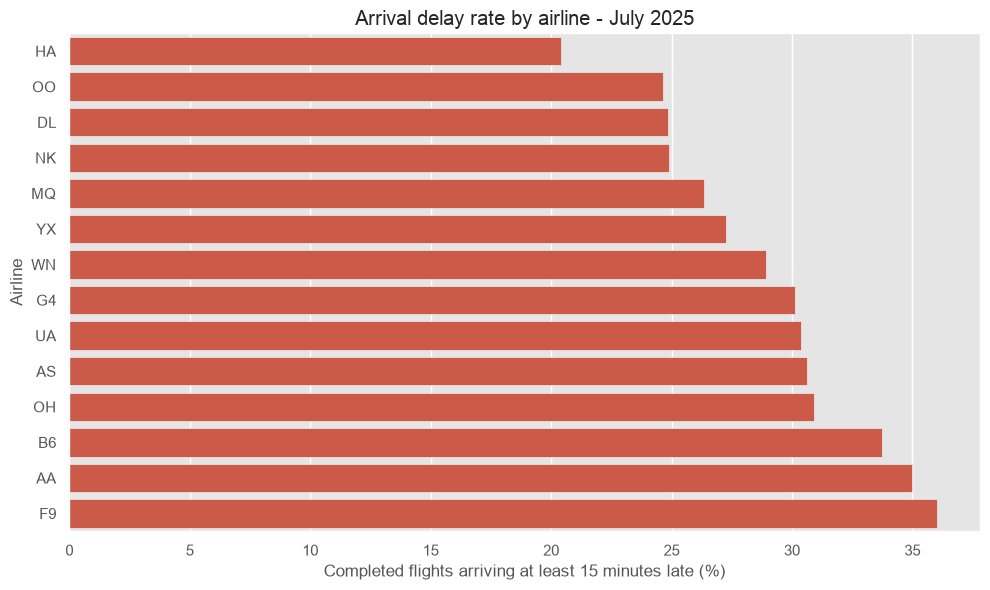

In [11]:
plot_data = airline_summary.reset_index()
plot_data['delay_percent'] = plot_data['delay_rate'] * 100

fig,ax = plt.subplots(figsize=(10,6))

sns.barplot(
    data=plot_data,
    x='delay_percent',
    y='Reporting_Airline',
    errorbar=None,
    ax=ax
)

ax.set(
    title='Arrival delay rate by airline - July 2025',
    xlabel='Completed flights arriving at least 15 minutes late (%)',
    ylabel='Airline'
)

plt.tight_layout()
plt.show()

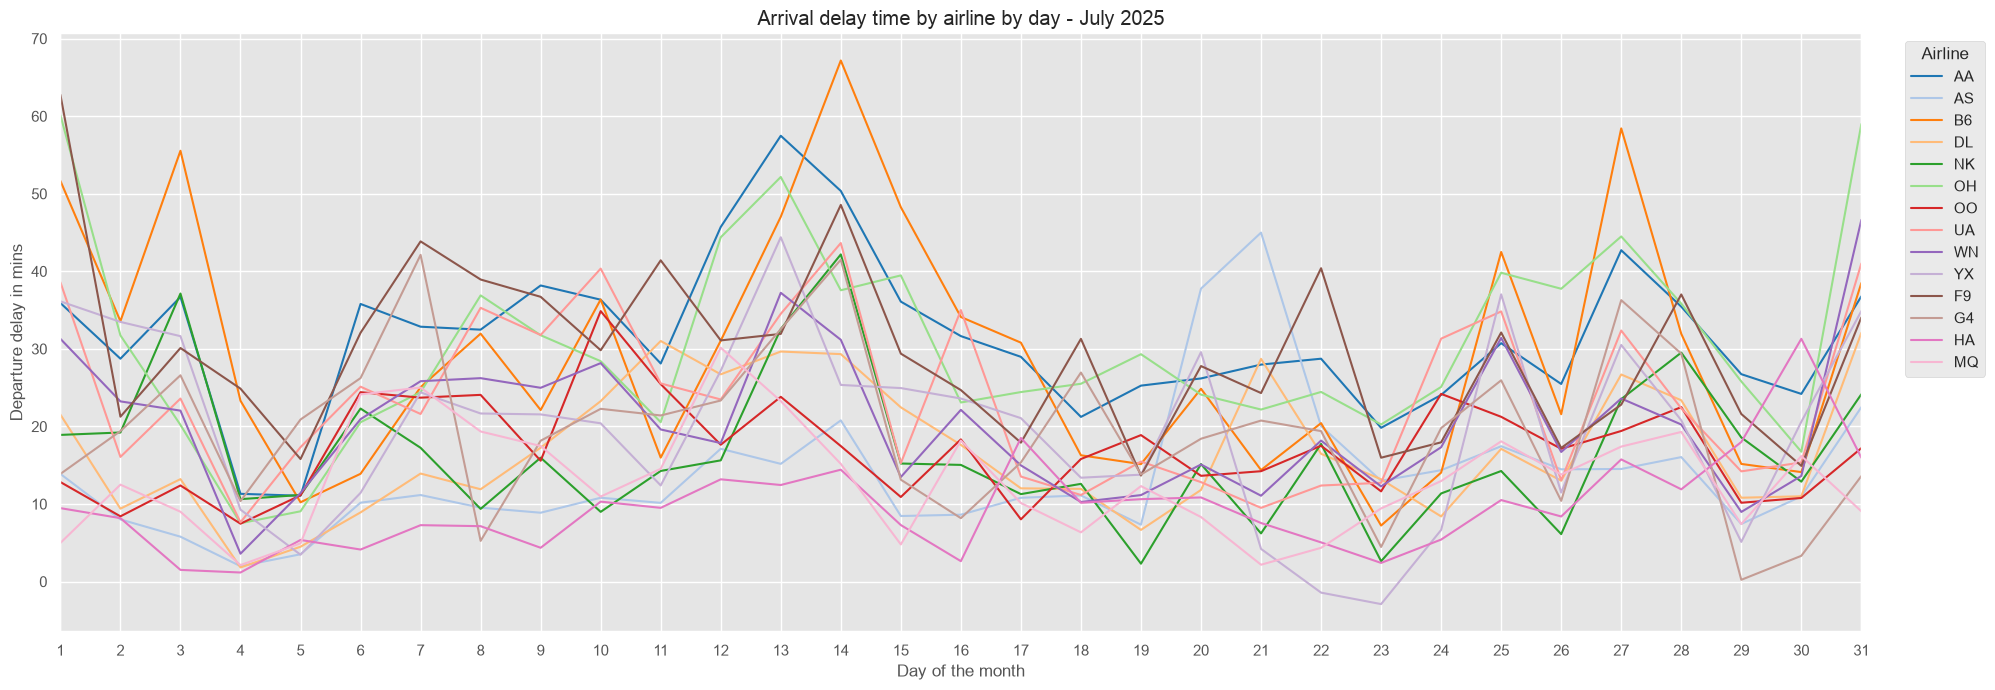

In [22]:
fig,ax = plt.subplots(figsize=(20,7))
sns.lineplot(
    data = completed,
    x='DayofMonth',
    y='DepDelay',
    hue='Reporting_Airline',
    estimator='mean',
    errorbar=None,
    palette='tab20',
    ax=ax
)
ax.set(
    title='Arrival delay time by airline by day - July 2025',
    xlabel='Day of the month',
    ylabel='Departure delay in mins'
)
ax.set_xticks(range(1,32))
ax.set_xlim(1,31)

ax.legend(
    title='Airline',
    bbox_to_anchor=(1.02,1),
    loc='upper left'
)
plt.tight_layout()
plt.show()